In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import os

os.chdir('/content/drive/MyDrive/CMPU 250 Group 6 Final Project/eda')
print(os.getcwd())

/content/drive/MyDrive/CMPU 250 Group 6 Final Project/eda


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
eurepoc = pd.read_csv('../data/eurepoc_global_dataset_1_3_EDITED.csv')

In [ ]:
# we remove unnecessary columns
eurepoc = eurepoc.drop(columns=[
    'number_attributions',
    'number_political_responses',
    'number_legal_responses',
    'receiver_country_alpha_2_code',
    'attribution_source_url',
    'initiator_alpha_2',
    'initiator_country.1',
    'initiator_category.1',
    'source_url',
    'attribution_legal_reference',
    'attribution_legal_reference_subcode',
    'added_to_db',
    'updated_at'
])

In [ ]:
def parse_list_with_parentheticals(cell):
    items = []
    last = 0
    depth = 0
    for i, c in enumerate(cell):
        if c == '(':
            depth += 1
        if c == ')':
            depth -= 1
        if c == ';' and depth <= 0:
            items.append(cell[last:i])
            depth = 0
            last = i + 1
    if cell[last:] != '':
        items.append(cell[last:])
    return items

# these columns contain semicolons but do not represent multiple entries per cell
ignored_columns = ['name', 'description', 'disruption', 'physical_effects_temporal']

# these columns are semicolon-delimited, but also occasionally contain semicolons in parentheticals
escaped_columns = ['receiver_name', 'initiator_name', 'attributing_actor', 'political_response_responding_actor']

for series_name, series in eurepoc.items():
    # if we trust column to be singleton (logan reference), we can ignore it
    if series_name in ignored_columns: continue
    # if column not of type string, proceed
    if series.dtype != 'str': continue

    if series_name in escaped_columns:
        # use a complicated and expensive operation when necessary
        lists = series.apply(lambda cell: parse_list_with_parentheticals(str(cell)))
    else:
        # otherwise a simple split works fine
        lists = series.apply(lambda cell: str.split(str(cell), ';'))

    # if series does not any list-formatted values, proceed
    if not lists.apply(lambda items: len(items) != 1).any(): continue

    eurepoc[series_name] = lists

In [ ]:
column_groups = [
    ['inclusion_criterion', 'inclusion_criterion_subcode'],
    ['source_disclosure'],
    ['incident_type'],
    ['receiver_name', 'receiver_country', 'receiver_regions', 'receiver_category', 'receiver_subcategory'],
    ['initiator_name', 'initiator_country', 'initiator_category', 'initiator_subcategory', 'attribution_id', 'attribution_date', 'attribution_type', 'attribution_basis', 'attributing_actor', 'attributing_company', 'attributing_country', 'settled_initiator'],
    ['cyber_conflict_issue'],
    ['offline_conflict_issue', 'offline_conflict_name', 'offline_conflict_intensity', 'offline_conflict_intensity_subcode'],
    ['political_response_date', 'political_response_type', 'political_response_subtype', 'political_response_responding_country', 'political_response_responding_actor'],
    ['il_breach_indicator', 'il_breach_indicator_subcode'],
    ['legal_response_date', 'legal_response_type', 'legal_response_subtype', 'legal_response_responding_country', 'legal_response_responding_actor'],
]

In [ ]:
def explode_group(columns):
    # select id and relevant columns, then explode on those columns
    df = eurepoc[['incident_id', *columns]].explode(columns, ignore_index=True)
    eurepoc.drop(columns=columns, inplace=True)
    return df

inclusion = explode_group(column_groups[0])
disclosure = explode_group(column_groups[1])
incident_type = explode_group(column_groups[2])
receiver = explode_group(column_groups[3])
initiator = explode_group(column_groups[4])
cyber_issue = explode_group(column_groups[5])
offline_issue = explode_group(column_groups[6])
political_response = explode_group(column_groups[7])
international_law = explode_group(column_groups[8])
legal_response = explode_group(column_groups[9])

In [ ]:
replace_not_available = lambda cell: None if cell == 'Not available' else cell
replace_not_attributed = lambda cell: None if cell == 'Not attributed' else cell

parse_dd_mm_yyyy = lambda cell: None if cell == 'Not available' else pd.to_datetime(cell, dayfirst=True)

In [ ]:
inclusion = inclusion.rename(columns={
    'incident_id': 'Incident',
    'inclusion_criterion': 'Criterion',
    'inclusion_criterion_subcode': 'Subcode',
})

inclusion.to_csv('../data/inclusion.csv')

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
disclosure = disclosure.rename(columns={
    'incident_id': 'Incident',
    'source_disclosure': 'Source'
})

disclosure.to_csv('../data/disclosure.csv')

In [ ]:
incident_type = incident_type.rename(columns={
    'incident_id': 'Incident',
    'incident_type': 'Type'
})

incident_type.to_csv('../data/incident_type.csv')

The receiver table requires some special handling since regions are *also* stored as packed lists. Thankfully, this is much easier than the table as a whole since there's only a single level.

In [ ]:
# parse regions into list
regions = receiver['receiver_regions'].apply(lambda cell: [region[1:-1] for region in str.split(cell[1:-1], ', ')])
# find the highest number of regions in a single cell
columns = regions.apply(lambda cell: len(cell)).max()
labels = ['Region ' + str(i + 1) for i in range(columns)]
# pad with None so we can zip into a our eventual series
regions = regions.apply(lambda cell: cell + [None] * (columns - len(cell)))
series = zip(*list(regions))

# set each column on receiver
for label, values in zip(labels, series):
    receiver[label] = values

# remove original
receiver = receiver.drop(columns=['receiver_regions'])

/tmp/ipykernel_679/3173449752.py:12: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  receiver[label] = values
/tmp/ipykernel_679/3173449752.py:12: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  receiver[label] = values
/tmp/ipykernel_679/3173449752.py:12: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  re

In [ ]:
receiver = receiver.rename(columns={
    'incident_id': 'Incident',
    'receiver_name': 'Name',
    'receiver_country': 'Country',
    'receiver_category': 'Category',
    'receiver_subcategory': 'Subcategory'
})

receiver = receiver.map(replace_not_available)

receiver.to_csv('../data/receiver.csv')

In [ ]:
initiator = initiator.rename(columns={
    'incident_id': 'Incident',
    'initiator_name': 'Name',
    'initiator_country': 'Country',
    'initiator_category': 'Category',
    'initiator_subcategory': 'Subcategory',
    'attribution_id': 'Attribution ID',
    'attribution_date': 'Attribution date',
    'attribution_type': 'Attribution type',
    'attribution_basis': 'Attribution basis',
    'attributing_actor': 'Attribution actor',
    'attributing_company': 'Attribution company',
    'attributing_country': 'Attribution country',
    'settled_initiator': 'Settled with initiator',
})

initiator[['Name', 'Country', 'Category']] = initiator[['Name', 'Country', 'Category']].map(replace_not_attributed)
initiator = initiator.map(replace_not_available)

initiator['Attribution date'] = pd.to_datetime(
    initiator['Attribution date']
    .astype('string')
    .str.split(';').str[0],
    format='%d.%m.%Y',
    errors='coerce'
)
initiator['Settled with initiator'] = initiator['Settled with initiator'].apply(bool)

initiator.to_csv('../data/initiator.csv')

In [ ]:
cyber_issue = cyber_issue.rename(columns={
    'incident_id': 'Incident',
    'cyber_conflict_issue': 'Issue'
})

cyber_issue.to_csv('../data/cyber_issue.csv')

In [ ]:
offline_issue = offline_issue.rename(columns={
    'incident_id': 'Incident',
    'offline_conflict_issue': 'Issue',
    'offline_conflict_name': 'Name',
    'offline_conflict_intensity': 'Intensity',
    'offline_conflict_intensity_subcode': 'Intensity Subcode'
})

offline_issue = offline_issue.map(replace_not_available)

offline_issue.to_csv('../data/offline_issue.csv')

In [ ]:
political_response = political_response.rename(columns={
    'incident_id': 'Incident',
    'political_response_date': 'Date',
    'political_response_type': 'Type',
    'political_response_subtype': 'Subtype',
    'political_response_responding_country': 'Country',
    'political_response_responding_actor': 'Actor'
})

political_response = political_response.map(replace_not_available)
political_response['Date'] = pd.to_datetime(
    political_response['Date']
    .astype('string')
    .str.split(';').str[0],
    format='%d.%m.%Y',
    errors='coerce'
)

political_response.to_csv('../data/political_response.csv')

In [ ]:
international_law = international_law.rename(columns={
    'incident_id': 'Incident',
    'il_breach_indicator': 'Indicator',
    'il_breach_indicator_subcode': 'Subcode'
})

international_law.to_csv('../data/international_law.csv')

In [ ]:
legal_response = legal_response.rename(columns={
    'incident_id': 'Incident',
    'legal_response_date': 'Date',
    'legal_response_type': 'Type',
    'legal_response_subtype': 'Subtype',
    'legal_response_responding_country': 'Country',
    'legal_response_responding_actor': 'Actor'
})

legal_response['Date'] = pd.to_datetime(
    legal_response['Date']
    .astype('string')
    .str.split(';')
    .apply(lambda dates: next(
        (d.strip() for d in dates if d.strip() not in ['Not available', '']),
        None
    ) if isinstance(dates, list) else None),
    errors='coerce',
    format='mixed'
)

legal_response[['Type', 'Subtype', 'Country', 'Actor']] = legal_response[['Type', 'Subtype', 'Country', 'Actor']].map(lambda value: None if value == 'Not available' else value)

legal_response.to_csv('../data/legal_response.csv')

In [ ]:
eurepoc = eurepoc.rename(columns={
    'incident_id': 'Incident id',
    'name': 'Name',
    'description': 'Description',
    'start_date': 'Start date',
    'end_date': 'End date',
    'zero_days': 'Zero days',
    'zero_days_subcode': 'Zero days subcode',
    'mitre_initial_access': 'MITRE initial access',
    'mitre_impact': 'MITRE impact',
    'user_interaction': 'User interaction',
    'has_disruption': 'Has disruption',
    'data_theft': 'Data theft',
    'disruption': 'Disruption',
    'hijacking': 'Hijacking',
    'physical_effects_spatial': 'Spatial-physical effects',
    'physical_effects_temporal': 'Temporal-physical effects',
    'unweighted_intensity': 'Unweighted intensity',
    'target_multiplier': 'Target multiplier',
    'weighted_intensity': 'Weighted intensity',
    'impact_indicator_label': 'Impact label',
    'impact_indicator_score': 'Impact score',
    'functional_impact': 'Functional impact',
    'intelligence_impact': 'Intelligence impact',
    'affected_entities': 'Affected entities',
    'affected_entities_value': 'Affected entities value',
    'affected_third_countries': 'Affected third countries',
    'affected_third_countries_value': 'Affected third countries value',
    'economic_impact': 'Economic impact',
    'economic_impact_value': 'Economic impact value',
    'economic_impact_currency': 'Economic impact currency',
    'state_responsibility_actor': 'State responsibility actor',
    'evidence_for_sanctions_indicator': 'Evidence for sanctions indicator',
    'response_indicator': 'Response indicator',
    'casualties': 'Casualties'
})

eurepoc = eurepoc.map(replace_not_available)

eurepoc['Start date'] = eurepoc['Start date'].apply(parse_dd_mm_yyyy)
eurepoc['End date'] = eurepoc['End date'].apply(parse_dd_mm_yyyy)

In [ ]:
eurepoc['Year'] = eurepoc['Start date'].apply(lambda date: date.year)
eurepoc = eurepoc[(2017 <= eurepoc['Year']) & (eurepoc['Year'] <= 2023)]

pre_2020_condition = eurepoc['Year'] < 2020

pre_2020 = eurepoc[pre_2020_condition]
post_2020 = eurepoc[~pre_2020_condition]

pre_2020.to_csv('../data/pre_2020.csv')
post_2020.to_csv('../data/post_2020.csv')

## Summary Statistics

The following tables summarize the main variables used to examine changes in recorded cyber incidents between 2017 and 2023

Our outcome variables measure the frequency, types, and impacts of recorded cyber incidents. Incident frequency is measured by the number of incidents per year, while weighted intensity, impact score, disruption, data theft, and functional impact describe their severity and consequences. We also plan to examine incident types, targets, and initiators to identify changes in cyberattack patterns.

Our key explanatory variables are the year of each incident and the time period (2017–2019 or 2020–2023). These allow us to compare recorded cyber incidents before and after 2020.

These variables help us examine whether cyber incident patterns changed during the period of growing generative AI development and accessibility. However, the dataset does not directly identify whether AI was used in an attack, so our analysis can describe changes over time but cannot establish that AI caused them.

### Numeric Outcome Variables: Weighted Intensity and Impact Score

In [ ]:
# Calculate descriptive statistics for the numeric measures of incident severity and impact
numeric_summary = eurepoc[
    ['Weighted intensity', 'Impact score']
].agg(['count', 'mean', 'median', 'std', 'min', 'max']).T

numeric_summary = numeric_summary.round(2)

display(numeric_summary)

,count,mean,median,std,min,max
Weighted intensity,1654.0,2.66,3.0,1.46,0.0,9.0
Impact score,1654.0,4.87,6.0,3.44,0.0,15.0


### Categorical Outcome Variables: Disruption, Data Theft, and Functional Impact


In [ ]:
# Examine how incidents are distributed across disruption, data theft, and functional impact categories
categorical_columns = [
    'Has disruption',
    'Data theft',
    'Functional impact'
]

for column in categorical_columns:
    print(f"\n{column}")

    # Count incidents in each category, including missing values
    summary = eurepoc[column].value_counts(
        dropna=False
    ).reset_index()

    summary.columns = ['Category', 'Count']

    # Calculate the percentage of all recorded incidents in each category
    summary['Percentage'] = (
        summary['Count'] / len(eurepoc) * 100
    ).round(2)

    display(summary)


Has disruption


,Category,Count,Percentage
0,False,1020,61.67
1,True,634,38.33



Data theft


,Category,Count,Percentage
0,None,666,40.27
1,For private / commercial targets: non-sensitiv...,600,36.28
2,For private / commercial targets: sensitive in...,234,14.15
3,none,154,9.31



Functional impact


,Category,Count,Percentage
0,No system interference/disruption,611,36.94
1,None,502,30.35
2,Days (< 7 days),212,12.82
3,Day (< 24h),206,12.45
4,Weeks (< 4 weeks),82,4.96
5,Months,41,2.48


### Explanatory Variable: Year and Annual Incident Frequency

In [ ]:
# Count recorded cyber incidents in each year from 2017 through 2023
yearly_summary = (
    eurepoc['Year']
    .value_counts()
    .sort_index()
    .reset_index()
)

# Convert years to integers so they display without decimal places
yearly_summary.columns = ['Year', 'Incident Count']

# Display years as whole numbers
yearly_summary['Year'] = yearly_summary['Year'].astype(int)

display(yearly_summary)

,Year,Incident Count
0,2017,135
1,2018,120
2,2019,91
3,2020,71
4,2021,160
5,2022,354
6,2023,723


### Explanatory Variable: Time Period (Pre-2020 vs. 2020–2023)

In [ ]:
# Compare incident frequency between the 2017–2019 and 2020–2023 periods
period_summary = pd.DataFrame({
    'Period': ['2017–2019', '2020–2023'],
    'Incident Count': [
        (eurepoc['Year'] < 2020).sum(),
        (eurepoc['Year'] >= 2020).sum()
    ],
    'Years': [3, 4]
})

# Calculate annual averages to account for the different lengths of the two periods
period_summary['Incidents per Year'] = (
    period_summary['Incident Count'] / period_summary['Years']
).round(2)

display(period_summary)

,Period,Incident Count,Years,Incidents per Year
0,2017–2019,346,3,115.33
1,2020–2023,1308,4,327.00


### Categorical Outcome Variable: Incident Type

In [ ]:
# Separate combined incident types into individual categories
incident_types_expanded = incident_type.copy()

incident_types_expanded['Type'] = (
    incident_types_expanded['Type'].str.split(';')
)

incident_types_expanded = incident_types_expanded.explode('Type')

# Remove extra spaces around category names
incident_types_expanded['Type'] = (
    incident_types_expanded['Type'].str.strip()
)

# Keep only incidents from our 2017–2023 analysis period
incident_types_expanded = incident_types_expanded[
    incident_types_expanded['Incident'].isin(eurepoc['Incident id'])
]

# Count unique incidents associated with each incident type
incident_type_summary = (
    incident_types_expanded.groupby('Type')['Incident']
    .nunique()
    .sort_values(ascending=False)
    .reset_index(name='Incident Count')
)

# Calculate the percentage of incidents associated with each type
incident_type_summary['Percentage'] = (
    incident_type_summary['Incident Count']
    / eurepoc['Incident id'].nunique() * 100
).round(2)

display(incident_type_summary)

,Type,Incident Count,Percentage
0,Hijacking with Misuse,1026,62.03
1,Data theft,644,38.94
2,Disruption,641,38.75
3,Ransomware,272,16.44
4,Hijacking without Misuse,241,14.57
5,Data theft & Doxing,192,11.61
6,Not available,1,0.06


### Categorical Outcome Variable: Target Category

In [ ]:
# Keep only target records associated with incidents from 2017–2023
receiver_filtered = receiver[
    receiver['Incident'].isin(eurepoc['Incident id'])
].copy()

# Separate multiple target categories stored in the same cell
receiver_filtered['Category'] = (
    receiver_filtered['Category'].str.split(';')
)

# Create one row for each target category
receiver_filtered = receiver_filtered.explode('Category')

# Remove extra spaces from category names
receiver_filtered['Category'] = (
    receiver_filtered['Category'].str.strip()
)

# Count unique incidents affecting each target category
target_summary = (
    receiver_filtered.groupby('Category')['Incident']
    .nunique()
    .sort_values(ascending=False)
    .reset_index(name='Incident Count')
)

# Calculate the percentage of incidents affecting each category
target_summary['Percentage'] = (
    target_summary['Incident Count']
    / eurepoc['Incident id'].nunique() * 100
).round(2)

display(target_summary)

,Category,Incident Count,Percentage
0,State institutions / political system,794,48.00
1,Critical infrastructure,764,46.19
2,Corporate Targets (corporate targets only code...,254,15.36
3,Education,109,6.59
4,Social groups,109,6.59
5,Media,104,6.29
6,Unknown,85,5.14
7,Science,52,3.14
8,End user(s) / specially protected groups,46,2.78
9,International / supranational organization,31,1.87


## Data Visualizations

### Visualization 1: Recorded Cyber Incidents by Year (2017–2023)



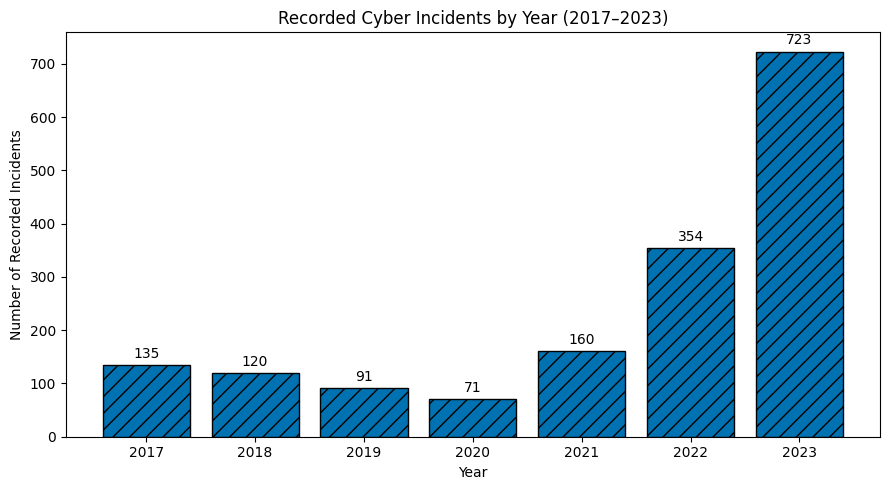

In [ ]:
# Plot the number of recorded cyber incidents for each year
fig, ax = plt.subplots(figsize=(9, 5))

bars = ax.bar(
    yearly_summary['Year'],
    yearly_summary['Incident Count'],
    color='#0072B2',
    edgecolor='black',
    hatch='//'
)

# Label the axes and add a descriptive title
ax.set_title('Recorded Cyber Incidents by Year (2017–2023)')
ax.set_xlabel('Year')
ax.set_ylabel('Number of Recorded Incidents')

# Display each year and start the vertical axis at zero
ax.set_xticks(yearly_summary['Year'])
ax.set_ylim(bottom=0)

# Display incident counts above each bar
ax.bar_label(bars, padding=3)

plt.tight_layout()
plt.show()


**Alt text:** Bar chart showing the number of recorded cyber incidents each year from 2017 to 2023. Counts are 135 in 2017, 120 in 2018, 91 in 2019, 71 in 2020, 160 in 2021, 354 in 2022, and 723 in 2023. The number of recorded incidents increases sharply after 2020, reaching its highest value in 2023.

### Visualization 2: Incident Types Before and After 2020


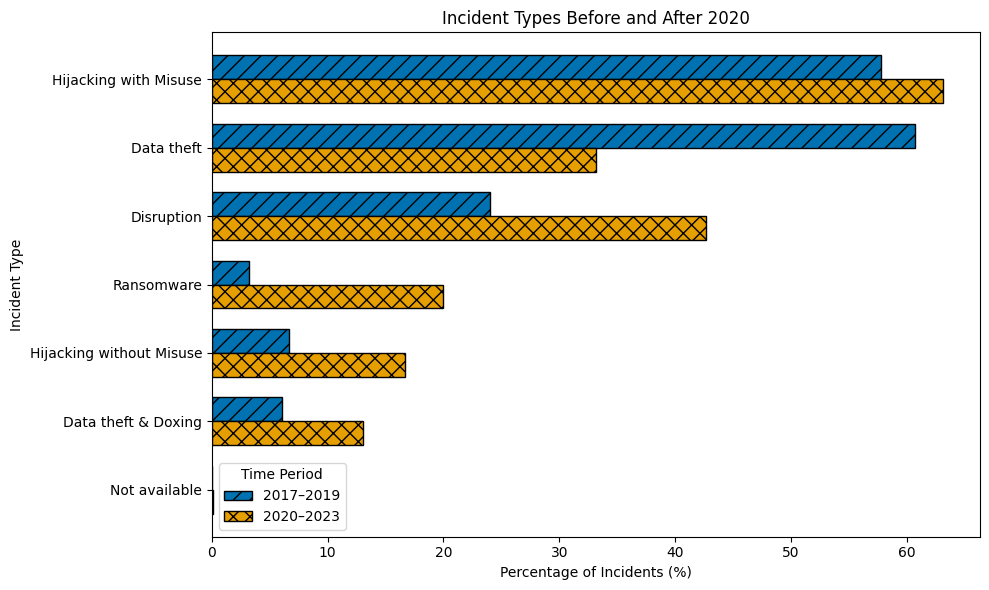

In [ ]:
# Match incident types with their corresponding years
incident_types_by_year = incident_types_expanded.merge(
    eurepoc[['Incident id', 'Year']],
    left_on='Incident',
    right_on='Incident id',
    how='inner'
)

# Assign each incident to a time period
incident_types_by_year['Period'] = np.where(
    incident_types_by_year['Year'] < 2020,
    '2017–2019',
    '2020–2023'
)

# Count unique incidents of each type in each period
type_counts = (
    incident_types_by_year
    .groupby(['Type', 'Period'])['Incident']
    .nunique()
    .unstack(fill_value=0)
)

# Calculate the total number of incidents in each period
period_totals = {
    '2017–2019': (eurepoc['Year'] < 2020).sum(),
    '2020–2023': (eurepoc['Year'] >= 2020).sum()
}

# Convert counts into percentages for a fair comparison
type_percentages = type_counts.copy()

for period in period_totals:
    type_percentages[period] = (
        type_counts[period] / period_totals[period] * 100
    )

# Sort categories by their overall frequency
type_percentages = type_percentages.loc[
    type_counts.sum(axis=1).sort_values(ascending=False).index
]

# Create a grouped horizontal bar chart
fig, ax = plt.subplots(figsize=(10, 6))

y = np.arange(len(type_percentages))
bar_height = 0.35

ax.barh(
    y - bar_height / 2,
    type_percentages['2017–2019'],
    height=bar_height,
    label='2017–2019',
    color='#0072B2',
    edgecolor='black',
    hatch='//'
)

ax.barh(
    y + bar_height / 2,
    type_percentages['2020–2023'],
    height=bar_height,
    label='2020–2023',
    color='#E69F00',
    edgecolor='black',
    hatch='xx'
)

ax.set_yticks(y)
ax.set_yticklabels(type_percentages.index)
ax.invert_yaxis()

ax.set_xlabel('Percentage of Incidents (%)')
ax.set_ylabel('Incident Type')
ax.set_title('Incident Types Before and After 2020')
ax.legend(title='Time Period')

plt.tight_layout()
plt.show()


**Alt text:** Grouped horizontal bar chart comparing the percentage of recorded cyber incidents associated with each incident type in 2017–2019 and 2020–2023. Blue hatched bars represent the earlier period, and orange cross-hatched bars represent the later period. Each category has two bars to show differences in the relative frequency of incident types across the two periods.

### Visualization 3: Average Weighted Intensity Before and After 2020

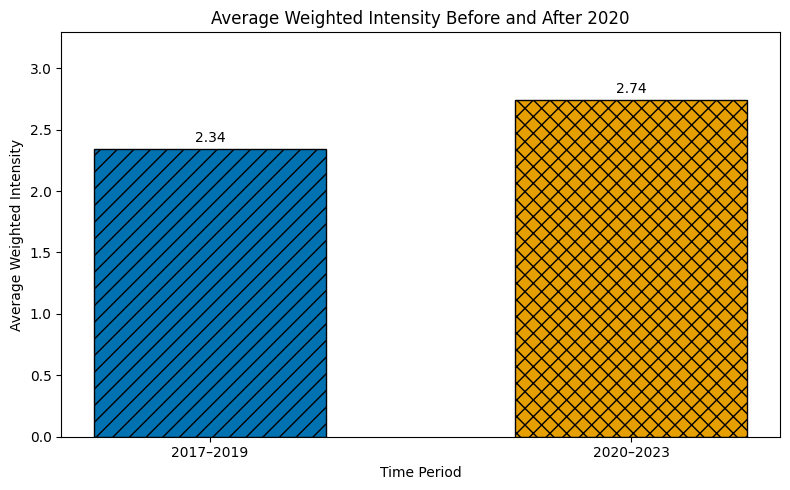

In [ ]:
# Create a time period for each incident
intensity_data = eurepoc[['Year', 'Weighted intensity']].copy()

intensity_data['Period'] = np.where(
    intensity_data['Year'] < 2020,
    '2017–2019',
    '2020–2023'
)

# Calculate average weighted intensity for each period
intensity_summary = (
    intensity_data.groupby('Period')['Weighted intensity']
    .mean()
    .reindex(['2017–2019', '2020–2023'])
)

# Create a bar chart comparing average weighted intensity
fig, ax = plt.subplots(figsize=(8, 5))

bars = ax.bar(
    intensity_summary.index,
    intensity_summary.values,
    color=['#0072B2', '#E69F00'],
    edgecolor='black',
    width=0.55
)

bars[0].set_hatch('//')
bars[1].set_hatch('xx')

# Add title and axis labels
ax.set_title('Average Weighted Intensity Before and After 2020')
ax.set_xlabel('Time Period')
ax.set_ylabel('Average Weighted Intensity')

# Start the vertical axis at zero
ax.set_ylim(bottom=0, top=intensity_summary.max() * 1.2)

# Display average values above each bar
ax.bar_label(bars, fmt='%.2f', padding=3)

plt.tight_layout()
plt.show()


**Alt text:** Bar chart comparing average weighted intensity of recorded cyber incidents in 2017–2019 and 2020–2023. A blue bar represents the earlier period and an orange bar represents the later period. The height of each bar indicates the average weighted intensity, with the numerical average displayed above it.

### Visualization 4: Target Categories Before and After 2020


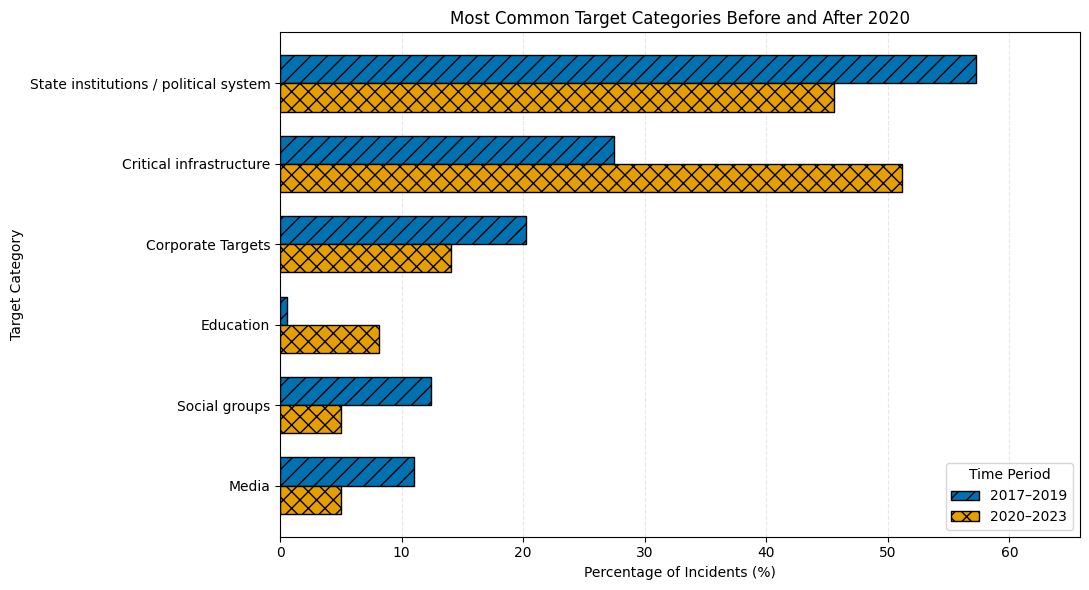

In [ ]:
# Match target categories with the year of each incident
targets_by_year = receiver_filtered.merge(
    eurepoc[['Incident id', 'Year']],
    left_on='Incident',
    right_on='Incident id',
    how='inner'
)

# Assign each incident to a time period
targets_by_year['Period'] = np.where(
    targets_by_year['Year'] < 2020,
    '2017–2019',
    '2020–2023'
)

# Count unique incidents affecting each target category
target_counts = (
    targets_by_year
    .groupby(['Category', 'Period'])['Incident']
    .nunique()
    .unstack(fill_value=0)
)

# Calculate percentages for each period
period_totals = {
    '2017–2019': (eurepoc['Year'] < 2020).sum(),
    '2020–2023': (eurepoc['Year'] >= 2020).sum()
}

target_percentages = target_counts.copy()

for period in period_totals:
    target_percentages[period] = (
        target_counts[period] / period_totals[period] * 100
    )

# Select the six most common target categories
top_categories = target_counts.sum(axis=1).nlargest(6).index
target_percentages = target_percentages.loc[top_categories]

# Shorten long category labels for readability
category_labels = [
    'Corporate Targets' if label.startswith('Corporate Targets')
    else label
    for label in target_percentages.index
]

# Create a grouped horizontal bar chart
fig, ax = plt.subplots(figsize=(11, 6))

y = np.arange(len(target_percentages))
bar_height = 0.35

ax.barh(
    y - bar_height / 2,
    target_percentages['2017–2019'],
    height=bar_height,
    label='2017–2019',
    color='#0072B2',
    edgecolor='black',
    hatch='//'
)

ax.barh(
    y + bar_height / 2,
    target_percentages['2020–2023'],
    height=bar_height,
    label='2020–2023',
    color='#E69F00',
    edgecolor='black',
    hatch='xx'
)

# Format the chart
ax.set_yticks(y)
ax.set_yticklabels(category_labels)
ax.invert_yaxis()

ax.set_xlabel('Percentage of Incidents (%)')
ax.set_ylabel('Target Category')
ax.set_title('Most Common Target Categories Before and After 2020')
ax.legend(title='Time Period', loc='lower right')

# Improve spacing and readability
ax.set_xlim(0, target_percentages.max().max() * 1.15)
ax.grid(axis='x', linestyle='--', alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()



**Alt text:** Grouped horizontal bar chart comparing the percentages of recorded cyber incidents affecting the six most common target categories in 2017–2019 and 2020–2023. Blue diagonally hatched bars represent the earlier period, while orange cross-hatched bars represent the later period. The categories include state institutions, critical infrastructure, corporate targets, education, social groups, and media.